In [ ]:
import numpy as np
import pandas as pd
df=pd.read_csv('/content/iris.csv')
df.head(5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [2]:
df.shape

(150, 5)

In [3]:
df.columns

Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='object')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [5]:
df.isnull().sum()

,0
sepal_length,0
sepal_width,0
petal_length,0
petal_width,0
species,0


In [6]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


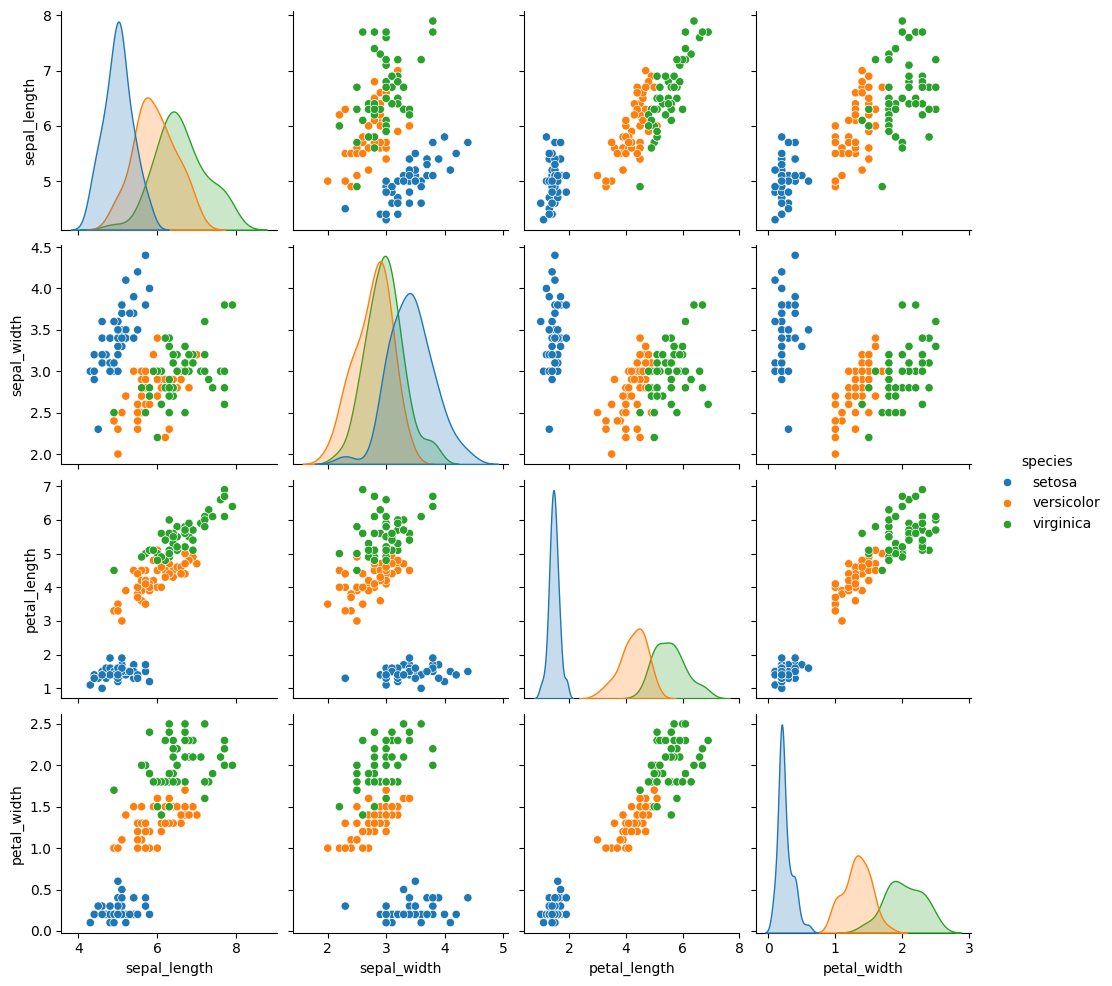

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(df, hue='species')
plt.show()

In [8]:
from sklearn.model_selection import train_test_split

# Input features
X = df.drop('species', axis=1)

# Target variable
y = df['species']

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (120, 4)
X_test: (30, 4)
y_train: (120,)
y_test: (30,)


In [9]:
from sklearn.preprocessing import StandardScaler

# Create scaler object
scaler = StandardScaler()

# Fit and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

In [10]:
print(X_train_scaled[:5])
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

[[-1.72156775 -0.33210111 -1.34572231 -1.32327558]
 [-1.12449223 -1.22765467  0.41450518  0.6517626 ]
 [ 1.14439475 -0.5559895   0.58484978  0.25675496]
 [-1.12449223  0.11567567 -1.28894078 -1.45494479]
 [-0.40800161 -1.22765467  0.13059752  0.12508575]]
Training shape: (120, 4)
Testing shape: (30, 4)


In [11]:
print("Mean:", X_train_scaled.mean(axis=0))

print("Standard Deviation:", X_train_scaled.std(axis=0))

Mean: [-1.36927506e-16  9.99200722e-16  1.66533454e-17  1.70234197e-16]
Standard Deviation: [1. 1. 1. 1.]


In [12]:
from sklearn.linear_model import LogisticRegression
model_lr = LogisticRegression(max_iter=1000)
model_lr.fit(X_train_scaled, y_train)
y_pred_lr = model_lr.predict(X_test_scaled)
print("Predicted values:")
print(y_pred_lr)

print("\nActual values:")
print(y_test.values)

Predicted values:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'versicolor'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']

Actual values:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'virginica'
 'virginica' 'versicolor' 'versicolor' 'setosa' 'virginica' 'setosa']


In [13]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", accuracy * 100, "%")

Logistic Regression Accuracy: 93.33333333333333 %


In [14]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [15]:
from sklearn.tree import DecisionTreeClassifier
model_dt = DecisionTreeClassifier(random_state=42)
model_dt.fit(X_train_scaled, y_train)
y_pred_dt = model_dt.predict(X_test_scaled)
from sklearn.metrics import accuracy_score

accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", accuracy_dt * 100, "%")


Decision Tree Accuracy: 93.33333333333333 %


In [16]:
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [17]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_dt
}

for name, pred in models.items():
    print(name)
    print("Accuracy:", accuracy_score(y_test, pred))
    print("Precision:", precision_score(y_test, pred, average='macro'))
    print("Recall:", recall_score(y_test, pred, average='macro'))
    print("F1 Score:", f1_score(y_test, pred, average='macro'))
    print("----------------------")

Logistic Regression
Accuracy: 0.9333333333333333
Precision: 0.9333333333333332
Recall: 0.9333333333333332
F1 Score: 0.9333333333333332
----------------------
Decision Tree
Accuracy: 0.9333333333333333
Precision: 0.9333333333333332
Recall: 0.9333333333333332
F1 Score: 0.9333333333333332
----------------------


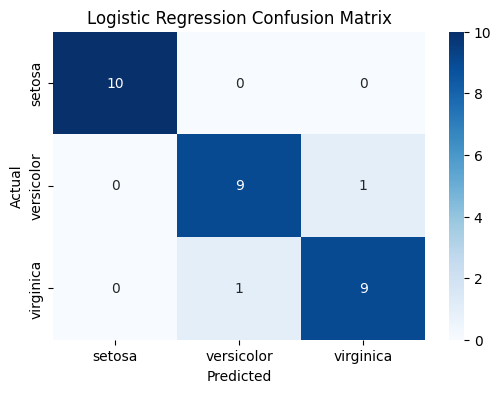

In [18]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6, 4))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues',
            xticklabels=model_lr.classes_,
            yticklabels=model_lr.classes_)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

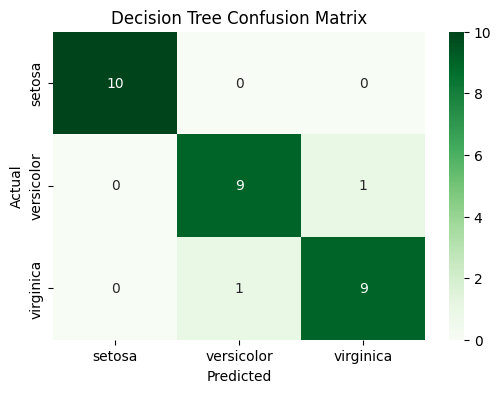

In [19]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(6, 4))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Greens',
            xticklabels=model_dt.classes_,
            yticklabels=model_dt.classes_)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [20]:
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
import numpy as np
import matplotlib.pyplot as plt

# First two features only
X_2d = df[['sepal_length', 'sepal_width']]
y = df['species']

# Split data
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d, y, test_size=0.2, random_state=42, stratify=y
)

# Scaling
scaler_2d = StandardScaler()
X_train_2d = scaler_2d.fit_transform(X_train_2d)

# Train models
lr_2d = LogisticRegression(max_iter=1000)
dt_2d = DecisionTreeClassifier(random_state=42)

lr_2d.fit(X_train_2d, y_train_2d)
dt_2d.fit(X_train_2d, y_train_2d)

print("2D models trained successfully!")

2D models trained successfully!


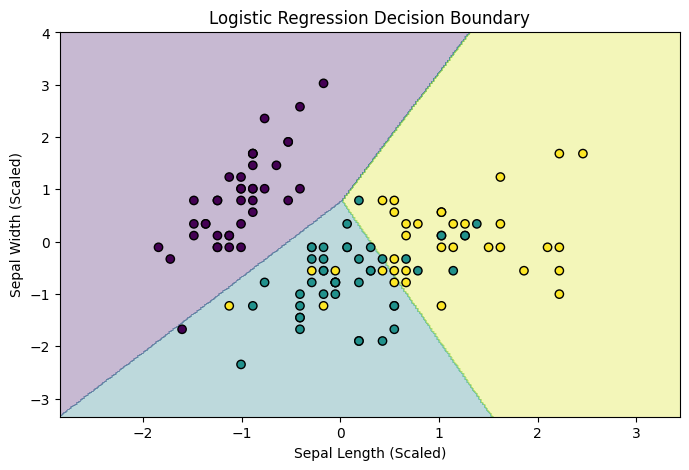

In [21]:
from matplotlib.colors import ListedColormap

def plot_decision_boundary(model, X, y, title):

    X = np.array(X)

    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, 0.02),
        np.arange(y_min, y_max, 0.02)
    )

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])

    class_map = {name: i for i, name in enumerate(model.classes_)}
    Z = np.array([class_map[label] for label in Z])
    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(8, 5))
    plt.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')

    plt.scatter(X[:, 0], X[:, 1],
                c=[class_map[label] for label in y],
                edgecolor='black', cmap='viridis')

    plt.title(title)
    plt.xlabel("Sepal Length (Scaled)")
    plt.ylabel("Sepal Width (Scaled)")
    plt.show()


plot_decision_boundary(
    lr_2d, X_train_2d, y_train_2d,
    "Logistic Regression Decision Boundary"
)

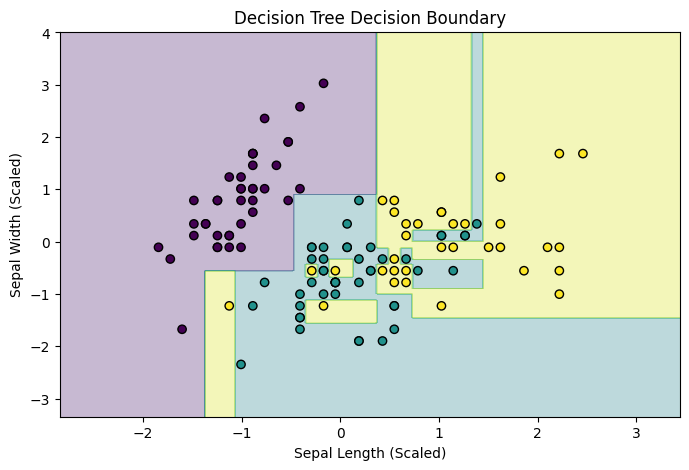

In [22]:
plot_decision_boundary(
    dt_2d,
    X_train_2d,
    y_train_2d,
    "Decision Tree Decision Boundary"
)

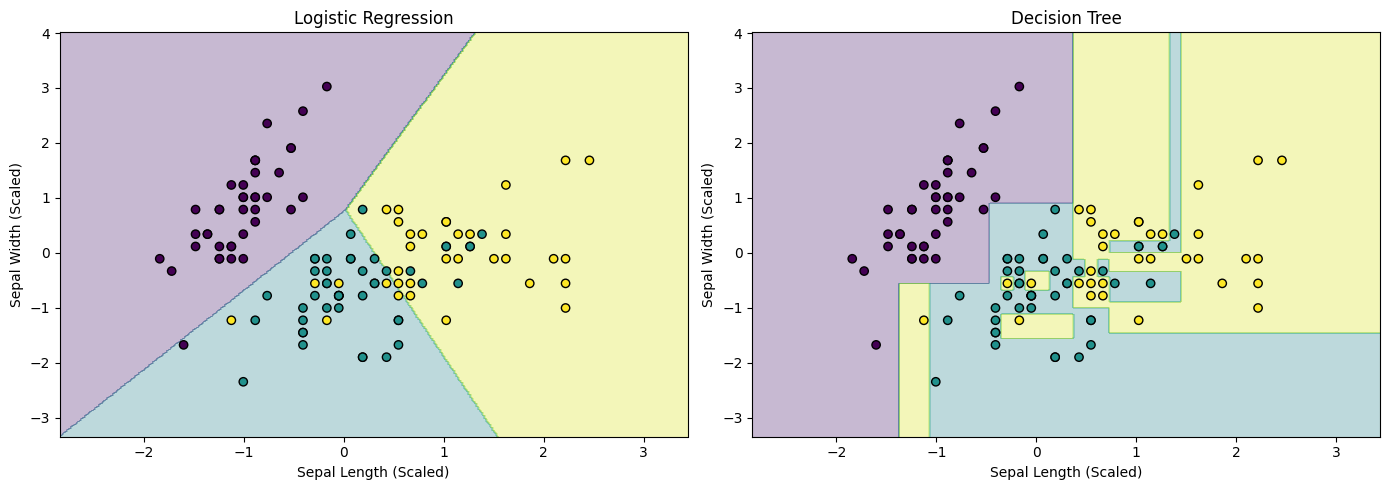

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

models_2d = [
    (lr_2d, "Logistic Regression"),
    (dt_2d, "Decision Tree")
]

class_map = {name: i for i, name in enumerate(lr_2d.classes_)}

for ax, (model, title) in zip(axes, models_2d):

    x_min, x_max = X_train_2d[:, 0].min() - 1, X_train_2d[:, 0].max() + 1
    y_min, y_max = X_train_2d[:, 1].min() - 1, X_train_2d[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, 0.02),
        np.arange(y_min, y_max, 0.02)
    )

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = np.array([class_map[label] for label in Z])
    Z = Z.reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')

    ax.scatter(
        X_train_2d[:, 0],
        X_train_2d[:, 1],
        c=[class_map[label] for label in y_train_2d],
        edgecolor='black',
        cmap='viridis'
    )

    ax.set_title(title)
    ax.set_xlabel("Sepal Length (Scaled)")
    ax.set_ylabel("Sepal Width (Scaled)")

plt.tight_layout()
plt.show()